(sec-2-1)=
# 2.1 Complex Numbers and Euler's Formula

Complex numbers can feel like an unexpected extra topic when the goal is to understand an ECG. I introduce them here because they give us a convenient way to describe the size and phase of an oscillation. Later, the same idea will help us read a Fourier spectrum and understand how a filter changes a signal.

We will begin with ordinary arithmetic and a picture of a number as an arrow. From there, we can work toward Euler's formula and use it in a small signal-analysis example. If the notation is unfamiliar, follow the numerical examples first; they give each symbol something concrete to refer to.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-2-1-1)=
## 2.1.1 The Imaginary Unit and the Complex Plane

The equation $x^2 + 1 = 0$ has no solution among the real numbers, because the square of any real number is non-negative. We extend the number system by *defining* a new quantity whose square is $-1$:

$$
j^2 = -1.
$$

Read $j^2=-1$ as a rule for arithmetic, rather than as a measured quantity. For example, $(2j)^2=4j^2=-4$. A complex number will still have two ordinary real coordinates; the symbol $j$ tells us which coordinate is the imaginary part.

Mathematicians call this number $i$. Electrical engineers use $j$ because $i$ is already taken by electric current, and I follow the engineering convention throughout the book. Python does the same: the literal `1j` is the imaginary unit.

A **complex number** combines a real part and an imaginary part,

$$
z = a + jb, \qquad a = \operatorname{Re}\{z\}, \quad b = \operatorname{Im}\{z\},
$$

where $a$ and $b$ are ordinary real numbers. Since $z$ is described by the pair $(a, b)$, we can draw it as a point, or an arrow from the origin, in a plane whose horizontal axis holds the real part and whose vertical axis holds the imaginary part. This is the **complex plane**.

The powers of $j$ repeat with period four, a fact we will need shortly:

$$
j^0 = 1,\quad j^1 = j,\quad j^2 = -1,\quad j^3 = j^2 \cdot j = -j,\quad j^4 = (j^2)^2 = 1,\quad j^5 = j, \;\ldots
$$

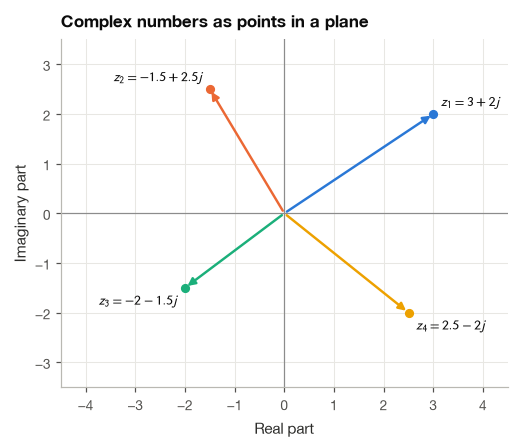

In [2]:
points = {"$z_1 = 3 + 2j$": 3 + 2j, "$z_2 = -1.5 + 2.5j$": -1.5 + 2.5j,
          "$z_3 = -2 - 1.5j$": -2 - 1.5j, "$z_4 = 2.5 - 2j$": 2.5 - 2j}

fig, ax = plt.subplots(figsize=(4.6, 4.2))
for k, (label, z) in enumerate(points.items()):
    ax.annotate("", xy=(z.real, z.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=C[k], lw=1.6))
    ax.plot(z.real, z.imag, "o", color=C[k], ms=5)
    ax.text(z.real + 0.15 * np.sign(z.real), z.imag + 0.25 * np.sign(z.imag), label,
            ha="left" if z.real > 0 else "right", va="center", fontsize=9)
ax.axhline(0, color="0.55", lw=0.8)
ax.axvline(0, color="0.55", lw=0.8)
ax.set(xlim=(-4.5, 4.5), ylim=(-3.5, 3.5), xlabel="Real part", ylabel="Imaginary part",
       title="Complex numbers as points in a plane")
ax.set_aspect("equal")
plt.show()

(sec-2-1-2)=
## 2.1.2 Arithmetic with Complex Numbers

### Addition and subtraction

Real parts are added to real parts and imaginary parts to imaginary parts:

$$
(a + jb) + (c + jd) = (a + c) + j(b + d).
$$

Geometrically this is vector addition: place the second arrow at the tip of the first.

### Multiplication

Multiplication follows the ordinary distributive law, with one extra rule, $j^2 = -1$:

$$
\begin{aligned}
(a + jb)(c + jd) &= ac + j\,ad + j\,bc + j^2\,bd \\
                 &= (ac - bd) + j\,(ad + bc).
\end{aligned}
$$

**Example 2.1.1.** Compute $(3 + 4j)(1 - 2j)$.

Expanding term by term,

$$
\begin{aligned}
(3 + 4j)(1 - 2j) &= 3\cdot 1 + 3\cdot(-2j) + 4j\cdot 1 + 4j\cdot(-2j) \\
                 &= 3 - 6j + 4j - 8j^2 \\
                 &= 3 - 2j + 8 \qquad (\text{since } -8j^2 = +8)\\
                 &= 11 - 2j.
\end{aligned}
$$

### The complex conjugate and the modulus

The **conjugate** of $z = a + jb$ flips the sign of the imaginary part, $z^* = a - jb$. It mirrors $z$ across the real axis. Multiplying a number by its own conjugate always gives a real, non-negative result:

$$
z\,z^* = (a + jb)(a - jb) = a^2 - jab + jab - j^2 b^2 = a^2 + b^2 .
$$

The square root of this quantity is the **modulus** (or magnitude) of $z$, the length of its arrow:

$$
|z| = \sqrt{z\,z^*} = \sqrt{a^2 + b^2}.
$$

### Division

To divide, we multiply the numerator and the denominator by the conjugate of the denominator. This turns the denominator into the real number $|w|^2$, after which the division is just scaling.

**Example 2.1.2.** Compute $\dfrac{3 + 4j}{1 - 2j}$.

$$
\begin{aligned}
\frac{3 + 4j}{1 - 2j} &= \frac{(3 + 4j)(1 + 2j)}{(1 - 2j)(1 + 2j)} \\[4pt]
&= \frac{3 + 6j + 4j + 8j^2}{1^2 + 2^2} \\[4pt]
&= \frac{(3 - 8) + 10j}{5} = \frac{-5 + 10j}{5} = -1 + 2j.
\end{aligned}
$$

A quick sanity check is to multiply back: $(-1 + 2j)(1 - 2j) = -1 + 2j + 2j - 4j^2 = 3 + 4j$, as it should be. Python's built-in `complex` type gives the same answers.

In [3]:
z = 3 + 4j
w = 1 - 2j

print(f"z * w        = {z * w}")
print(f"z / w        = {z / w}")
print(f"conj(z)      = {z.conjugate()}")
print(f"|z|          = {abs(z)}")
print(f"z * conj(z)  = {z * z.conjugate()}")

z * w        = (11-2j)
z / w        = (-1+2j)
conj(z)      = (3-4j)
|z|          = 5.0
z * conj(z)  = (25+0j)


(sec-2-1-3)=
## 2.1.3 Polar Form

The rectangular description $(a, b)$ is convenient for addition. For multiplication, and for oscillations in general, a second description is far more natural: the length $r$ of the arrow and the angle $\theta$ it makes with the positive real axis.

From the right triangle formed by $a$, $b$ and the arrow,

$$
a = r\cos\theta, \qquad b = r\sin\theta, \qquad r = \sqrt{a^2 + b^2}, \qquad \theta = \operatorname{atan2}(b, a).
$$

The angle $\theta$ is called the **argument** or **phase** of $z$, written $\arg z$. The two-argument function $\operatorname{atan2}(b, a)$ is used instead of $\arctan(b/a)$ because the ratio $b/a$ forgets which quadrant the point lies in.

**Example 2.1.3.** Find the polar form of $z = -1 - j$.

The modulus is $r = \sqrt{(-1)^2 + (-1)^2} = \sqrt{2}$. The naive calculation $\arctan\!\big((-1)/(-1)\big) = \arctan(1) = \pi/4$ points into the first quadrant, which is wrong: both parts of $z$ are negative, so $z$ lies in the third quadrant. Adding $-\pi$ to move into the correct quadrant gives $\theta = \pi/4 - \pi = -3\pi/4$. NumPy's `np.angle` uses `atan2` internally and gets this right automatically.

In [4]:
z = -1 - 1j
print(f"r = |z|              = {np.abs(z):.4f}   (sqrt(2) = {np.sqrt(2):.4f})")
print(f"arctan(b/a)          = {np.arctan(z.imag / z.real):+.4f} rad  (wrong quadrant)")
print(f"np.angle(z)          = {np.angle(z):+.4f} rad")
print(f"-3*pi/4              = {-3 * np.pi / 4:+.4f} rad")

r = |z|              = 1.4142   (sqrt(2) = 1.4142)
arctan(b/a)          = +0.7854 rad  (wrong quadrant)
np.angle(z)          = -2.3562 rad
-3*pi/4              = -2.3562 rad


(sec-2-1-4)=
## 2.1.4 Euler's Formula

The polar form becomes truly useful once we connect it to the exponential function. **Euler's formula** states that for any real angle $\theta$,

(eq-2-1)=
\begin{equation*}
e^{j\theta} = \cos\theta + j\sin\theta. \tag{2.1}
\end{equation*}

I think it is worth seeing why this is true rather than taking it on faith, and the cleanest route I know is through Taylor series.

**Step 1: write down three familiar series.** For every real $x$,

$$
\begin{aligned}
e^{x}     &= 1 + x + \frac{x^2}{2!} + \frac{x^3}{3!} + \frac{x^4}{4!} + \frac{x^5}{5!} + \cdots \\
\cos x    &= 1 - \frac{x^2}{2!} + \frac{x^4}{4!} - \frac{x^6}{6!} + \cdots \\
\sin x    &= x - \frac{x^3}{3!} + \frac{x^5}{5!} - \frac{x^7}{7!} + \cdots
\end{aligned}
$$

The cosine keeps only the even powers and the sine only the odd powers, each with alternating signs.

**Step 2: substitute $x = j\theta$ into the exponential series.** The exponential series converges for complex arguments as well, so we may write

$$
e^{j\theta} = 1 + j\theta + \frac{(j\theta)^2}{2!} + \frac{(j\theta)^3}{3!} + \frac{(j\theta)^4}{4!} + \frac{(j\theta)^5}{5!} + \cdots
$$

**Step 3: simplify the powers of $j$.** Using the four-step cycle $j^2 = -1$, $j^3 = -j$, $j^4 = 1$, $j^5 = j$ from [Section 2.1.1](#sec-2-1-1),

$$
e^{j\theta} = 1 + j\theta - \frac{\theta^2}{2!} - j\frac{\theta^3}{3!} + \frac{\theta^4}{4!} + j\frac{\theta^5}{5!} - \cdots
$$

**Step 4: collect the real and imaginary terms.**

$$
e^{j\theta} = \underbrace{\left(1 - \frac{\theta^2}{2!} + \frac{\theta^4}{4!} - \cdots\right)}_{\cos\theta}
 + j\underbrace{\left(\theta - \frac{\theta^3}{3!} + \frac{\theta^5}{5!} - \cdots\right)}_{\sin\theta}.
$$

The two brackets are exactly the series for $\cos\theta$ and $\sin\theta$ from Step 1, which proves equation [(2.1)](#eq-2-1).

We can watch this happen numerically. The next cell adds the terms of the series one at a time for $\theta = 2$ rad and plots each partial sum. The path starts at 1, overshoots, and spirals onto the point $\cos 2 + j\sin 2$ on the unit circle.

In [5]:
from math import factorial

theta = 2.0
terms = np.array([(1j * theta) ** n / factorial(n) for n in range(14)])
partial_sums = np.cumsum(terms)

exact = np.exp(1j * theta)
print(f"exact e^(j*2)        = {exact:.6f}")
print(f"cos(2) + j sin(2)    = {np.cos(theta) + 1j * np.sin(theta):.6f}")
print(f"partial sum, 14 terms = {partial_sums[-1]:.6f}")

exact e^(j*2)        = -0.416147+0.909297j
cos(2) + j sin(2)    = -0.416147+0.909297j
partial sum, 14 terms = -0.416147+0.909297j


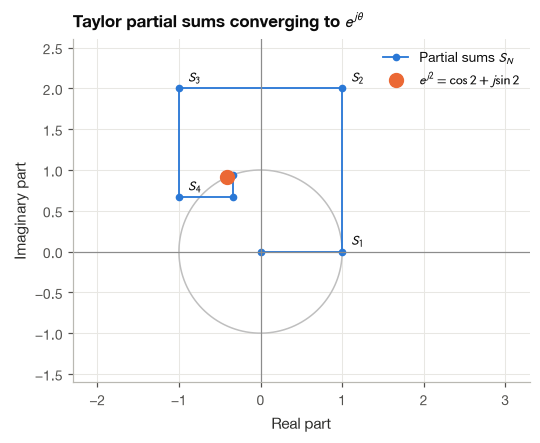

In [6]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
circle = np.exp(1j * np.linspace(0, 2 * np.pi, 400))
ax.plot(circle.real, circle.imag, color="0.75", lw=1)
path = np.concatenate([[0], partial_sums])
ax.plot(path.real, path.imag, "-o", color=C[0], ms=4, lw=1.2, label="Partial sums $S_N$")
ax.plot(exact.real, exact.imag, "o", color=C[1], ms=9, label=r"$e^{j2} = \cos 2 + j\sin 2$")
for n in (1, 2, 3, 4):
    ax.annotate(f"$S_{n}$", (partial_sums[n - 1].real, partial_sums[n - 1].imag),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.axhline(0, color="0.55", lw=0.8)
ax.axvline(0, color="0.55", lw=0.8)
ax.set(xlabel="Real part", ylabel="Imaginary part", xlim=(-2.3, 3.3), ylim=(-1.6, 2.6),
       title="Taylor partial sums converging to $e^{j\\theta}$")
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.show()

### Consequences of Euler's formula

Several results follow immediately and will be used throughout the book.

**The unit circle.** Since $|e^{j\theta}|^2 = \cos^2\theta + \sin^2\theta = 1$, the number $e^{j\theta}$ always lies on the circle of radius one. As $\theta$ grows, it moves counterclockwise around that circle.

**Compact polar form.** Combining $a = r\cos\theta$ and $b = r\sin\theta$ with equation [(2.1)](#eq-2-1),

$$
z = a + jb = r(\cos\theta + j\sin\theta) = r\,e^{j\theta}.
$$

**Cosine and sine as complex exponentials.** Replacing $\theta$ by $-\theta$ in [(2.1)](#eq-2-1), and using the fact that cosine is even and sine is odd, gives $e^{-j\theta} = \cos\theta - j\sin\theta$. Adding and subtracting the two versions,

(eq-2-2)=
\begin{equation*}
\begin{aligned}
e^{j\theta} + e^{-j\theta} &= 2\cos\theta &&\Longrightarrow\quad \cos\theta = \frac{e^{j\theta} + e^{-j\theta}}{2}, \\[4pt]
e^{j\theta} - e^{-j\theta} &= 2j\sin\theta &&\Longrightarrow\quad \sin\theta = \frac{e^{j\theta} - e^{-j\theta}}{2j}.
\end{aligned} \tag{2.2}
\end{equation*}

Equation [(2.2)](#eq-2-2) says that every real cosine is the sum of two complex exponentials spinning in opposite directions. This is the reason the spectrum of a real-valued signal always has a mirror image at negative frequencies.

**Euler's identity.** Setting $\theta = \pi$ gives $e^{j\pi} = \cos\pi + j\sin\pi = -1$, often written $e^{j\pi} + 1 = 0$.

(sec-2-1-5)=
## 2.1.5 Multiplication as Rotation and Scaling

In polar form, multiplication becomes simple. With $z_1 = r_1 e^{j\theta_1}$ and $z_2 = r_2 e^{j\theta_2}$, the ordinary law of exponents gives

$$
z_1 z_2 = r_1 e^{j\theta_1}\, r_2 e^{j\theta_2} = (r_1 r_2)\, e^{j(\theta_1 + \theta_2)}.
$$

*Magnitudes multiply and angles add.* Multiplying by $j = e^{j\pi/2}$, for example, rotates any number by a quarter turn without changing its length. Multiplying repeatedly by a number with modulus slightly less than one produces a spiral that turns and shrinks at every step, the discrete-time version of a damped oscillation that we will meet again when studying system stability in Chapter 11.

Applying the same rule $n$ times to $e^{j\theta}$ gives **De Moivre's formula**,

$$
\left(e^{j\theta}\right)^n = e^{jn\theta} = \cos(n\theta) + j\sin(n\theta).
$$

### Roots of unity

Which complex numbers satisfy $z^N = 1$? Writing $z = r e^{j\theta}$, the condition becomes $r^N e^{jN\theta} = 1 = e^{j2\pi k}$ for any integer $k$. Matching modulus and angle gives $r = 1$ and $\theta = 2\pi k / N$. There are exactly $N$ distinct solutions,

$$
W_N^{\,k} = e^{\,j2\pi k/N}, \qquad k = 0, 1, \ldots, N-1,
$$

equally spaced around the unit circle. These **$N$-th roots of unity** are the building blocks of the discrete Fourier transform.

They also sum to zero. With $w = e^{j2\pi/N} \ne 1$, the finite geometric series formula gives

$$
\sum_{k=0}^{N-1} w^k = \frac{1 - w^N}{1 - w} = \frac{1 - e^{j2\pi}}{1 - w} = \frac{1 - 1}{1 - w} = 0 .
$$

Geometrically, $N$ unit arrows spread evenly around a circle cancel each other perfectly. This single fact is what makes the DFT basis orthogonal, as we will show in Section 10.2.

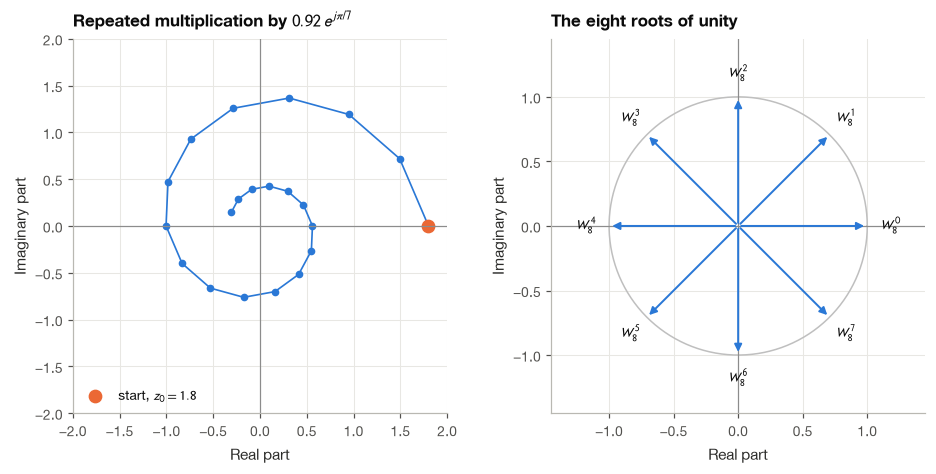

Sum of the 8 roots of unity: -3.45e-16+1.14e-17j


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.2))

ax = axes[0]
step = 0.92 * np.exp(1j * np.pi / 7)
z = 1.8 + 0.0j
seq = [z]
for _ in range(20):
    z = z * step
    seq.append(z)
seq = np.array(seq)
ax.plot(seq.real, seq.imag, "-o", color=C[0], ms=4, lw=1.1)
ax.plot(seq[0].real, seq[0].imag, "o", color=C[1], ms=8, label="start, $z_0 = 1.8$")
ax.set(title=r"Repeated multiplication by $0.92\,e^{j\pi/7}$", xlabel="Real part", ylabel="Imaginary part",
       xlim=(-2, 2), ylim=(-2, 2))
ax.legend(loc="lower left")

ax = axes[1]
N = 8
roots = np.exp(1j * 2 * np.pi * np.arange(N) / N)
ax.plot(circle.real, circle.imag, color="0.75", lw=1)
for k, r in enumerate(roots):
    ax.annotate("", xy=(r.real, r.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=C[0], lw=1.3))
    ax.text(1.18 * r.real, 1.18 * r.imag, f"$W_8^{k}$", ha="center", va="center", fontsize=9)
ax.set(title="The eight roots of unity", xlabel="Real part", ylabel="Imaginary part",
       xlim=(-1.45, 1.45), ylim=(-1.45, 1.45))

for ax in axes:
    ax.axhline(0, color="0.55", lw=0.8)
    ax.axvline(0, color="0.55", lw=0.8)
    ax.set_aspect("equal")
plt.show()

print(f"Sum of the 8 roots of unity: {roots.sum():.2e}")

(sec-2-1-6)=
## 2.1.6 Rotating Phasors and Real Sinusoids

Now let the angle grow linearly with time, $\theta = \omega t$, where $\omega$ is an angular frequency in radians per second. The complex exponential

$$
e^{j\omega t} = \cos(\omega t) + j\sin(\omega t)
$$

is a point moving around the unit circle at a constant speed, completing one revolution every $T = 2\pi/\omega$ seconds. Its real part, the shadow it casts on the horizontal axis, is a cosine.

A general sinusoid with amplitude $A$, frequency $\omega$ and phase $\varphi$ can therefore be written as

$$
x(t) = A\cos(\omega t + \varphi) = \operatorname{Re}\left\{A e^{j(\omega t + \varphi)}\right\} = \operatorname{Re}\left\{\underbrace{A e^{j\varphi}}_{X}\; e^{j\omega t}\right\}.
$$

The complex constant $X = A e^{j\varphi}$ is called the **phasor** of the sinusoid. It packs the two numbers that distinguish one sinusoid from another at the same frequency, its amplitude $|X| = A$ and its phase $\arg X = \varphi$, into a single complex number. When a sinusoid passes through a filter, the filter changes exactly these two numbers, which is why filter behavior is described by complex-valued frequency responses in Section 8.4.

The figure below follows a phasor rotating at $f = 1.2$ Hz (a heart rate of 72 beats per minute) for one full period. The left panel shows its path in the complex plane, and the right panel shows its real part as a function of time.

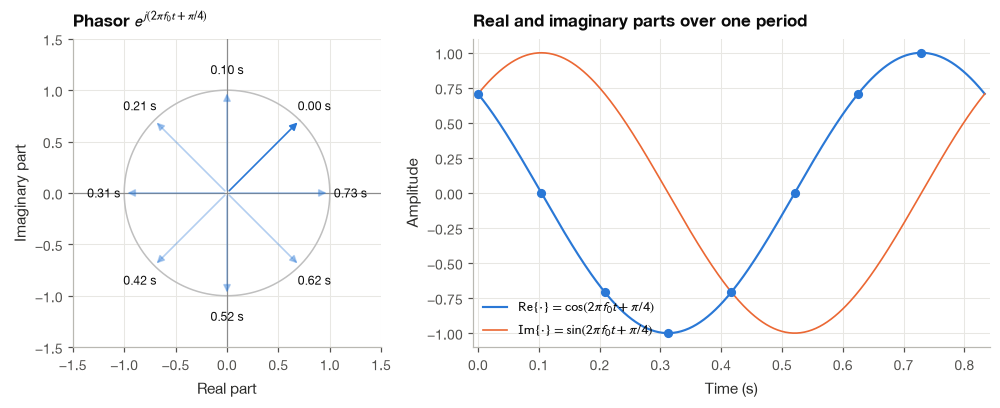

In [8]:
f0, A, phi = 1.2, 1.0, np.pi / 4
T = 1 / f0
t = np.linspace(0, T, 400)
phasor = A * np.exp(1j * (2 * np.pi * f0 * t + phi))
t_marks = np.arange(0, 8) * T / 8
marks = A * np.exp(1j * (2 * np.pi * f0 * t_marks + phi))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.plot(phasor.real, phasor.imag, color="0.75", lw=1)
for k, m in enumerate(marks):
    ax.annotate("", xy=(m.real, m.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=C[0], lw=1.1, alpha=0.35 + 0.65 * (k == 0)))
    ax.text(1.2 * m.real, 1.2 * m.imag, f"{t_marks[k]:.2f} s", ha="center", va="center", fontsize=8)
ax.axhline(0, color="0.55", lw=0.8)
ax.axvline(0, color="0.55", lw=0.8)
ax.set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), xlabel="Real part", ylabel="Imaginary part",
       title=r"Phasor $e^{j(2\pi f_0 t + \pi/4)}$")
ax.set_aspect("equal")

ax = axes[1]
ax.plot(t, phasor.real, color=C[0], label=r"$\mathrm{Re}\{\cdot\} = \cos(2\pi f_0 t + \pi/4)$")
ax.plot(t, phasor.imag, color=C[1], lw=1.1, label=r"$\mathrm{Im}\{\cdot\} = \sin(2\pi f_0 t + \pi/4)$")
ax.plot(t_marks, marks.real, "o", color=C[0], ms=5)
ax.set(xlabel="Time (s)", ylabel="Amplitude", title="Real and imaginary parts over one period")
ax.legend(loc="lower left")
plt.show()

(sec-2-1-7)=
## 2.1.7 Complex Numbers at Work: Measuring a Brain Rhythm

I close the section with an example that uses everything above. Suppose an EEG electrode over the occipital cortex records a dominant alpha rhythm at 10 Hz together with a weaker theta component at 6 Hz and broadband background activity. We would like to know the amplitude and phase of the alpha component.

Multiply the signal by $e^{-j\omega_0 t}$, with $\omega_0 = 2\pi f_0$, and average. To see why this works, take a single component $A\cos(\omega_0 t + \varphi)$ and expand it with equation [(2.2)](#eq-2-2):

$$
\begin{aligned}
A\cos(\omega_0 t + \varphi)\, e^{-j\omega_0 t}
&= \frac{A}{2}\left(e^{j(\omega_0 t + \varphi)} + e^{-j(\omega_0 t + \varphi)}\right) e^{-j\omega_0 t} \\[4pt]
&= \frac{A}{2} e^{j\varphi} \;+\; \frac{A}{2} e^{-j(2\omega_0 t + \varphi)} .
\end{aligned}
$$

The first term is a constant. The second term rotates at twice the frequency and averages to zero over any whole number of its periods. So the average of the product equals $\tfrac{A}{2}e^{j\varphi}$, and doubling it recovers the phasor $A e^{j\varphi}$. Components at other frequencies leave a residual rotation after the multiplication, and they also average away. Multiplying by a complex exponential works like a tuning dial that picks out one frequency.

For a sampled signal $x[n] = x(n/f_s)$ with $N$ samples, the average becomes a sum,

(eq-2-3)=
\begin{equation*}
\hat{X}(f_0) = \frac{2}{N}\sum_{n=0}^{N-1} x[n]\, e^{-j2\pi f_0 n / f_s}. \tag{2.3}
\end{equation*}

In [9]:
fs = 256                       # sampling rate (Hz)
duration = 4.0                 # seconds
t = np.arange(0, duration, 1 / fs)

alpha = 20 * np.cos(2 * np.pi * 10 * t + np.pi / 3)   # 20 uV, phase pi/3
theta = 8 * np.cos(2 * np.pi * 6 * t - np.pi / 2)     # 8 uV
background = rng.normal(0, 8, t.size)                 # broadband activity
eeg = alpha + theta + background


def phasor_at(x, f0, fs):
    """Estimate the phasor of the f0 component of x using equation (2.3)."""
    n = np.arange(x.size)
    return 2 / x.size * np.sum(x * np.exp(-2j * np.pi * f0 * n / fs))


X10 = phasor_at(eeg, 10, fs)
print(f"Estimated phasor at 10 Hz : {X10:.3f}")
print(f"Amplitude                 : {abs(X10):.2f} uV   (true 20 uV)")
print(f"Phase                     : {np.angle(X10):.3f} rad (true pi/3 = {np.pi / 3:.3f} rad)")

Estimated phasor at 10 Hz : 8.984+17.699j
Amplitude                 : 19.85 uV   (true 20 uV)
Phase                     : 1.101 rad (true pi/3 = 1.047 rad)


The estimate lands close to the true amplitude and phase even though the alpha rhythm is buried in background activity. If we repeat the calculation for many frequencies, the magnitude $|\hat{X}(f)|$ traces out the amplitude spectrum of the recording, with peaks at the two rhythms.

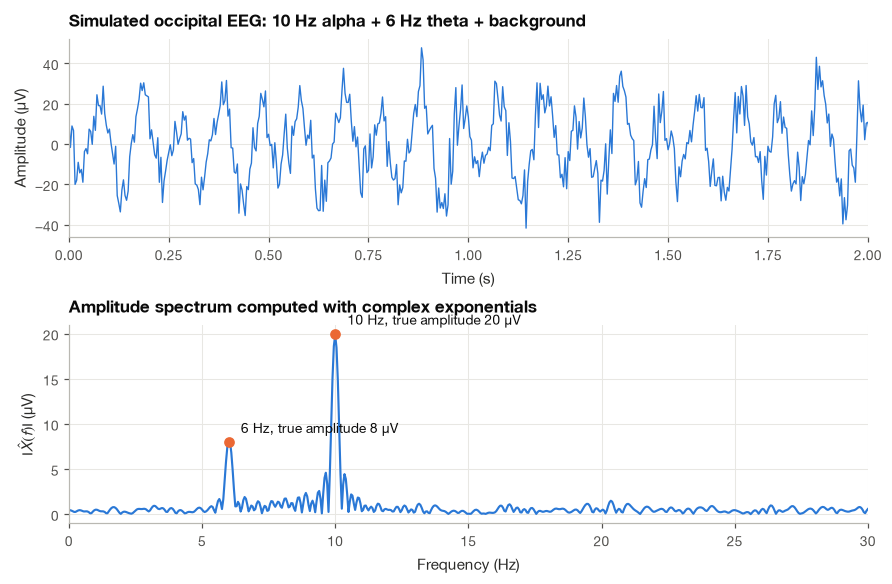

In [10]:
freqs = np.arange(0, 30.01, 0.05)
spectrum = np.array([phasor_at(eeg, f, fs) for f in freqs])

fig, axes = plt.subplots(2, 1, figsize=(8, 5.2))
axes[0].plot(t, eeg, color=C[0], lw=0.9)
axes[0].set(xlim=(0, 2), xlabel="Time (s)", ylabel="Amplitude (µV)",
            title="Simulated occipital EEG: 10 Hz alpha + 6 Hz theta + background")

axes[1].plot(freqs, np.abs(spectrum), color=C[0])
for f_peak, A_true in [(6, 8), (10, 20)]:
    axes[1].plot(f_peak, A_true, "o", color=C[1], ms=6)
    axes[1].annotate(f"{f_peak} Hz, true amplitude {A_true} µV", (f_peak, A_true),
                     textcoords="offset points", xytext=(8, 6), fontsize=9)
axes[1].set(xlabel="Frequency (Hz)", ylabel=r"$|\hat{X}(f)|$ (µV)",
            title="Amplitude spectrum computed with complex exponentials", xlim=(0, 30))
plt.show()

What we have just computed by hand, one frequency at a time, is essentially the discrete Fourier transform. Chapter 10 formalizes the idea, explains which frequencies to evaluate, and shows how the fast Fourier transform does the whole job in $O(N\log N)$ operations. The small ripples around each peak are a first glimpse of **spectral leakage**, the subject of Section 10.4.

## Summary

A complex number $z = a + jb$ can be read as a point in a plane, and the same point can be described by a length and an angle, $z = r e^{j\theta}$. Euler's formula $e^{j\theta} = \cos\theta + j\sin\theta$ links the two descriptions and follows directly from the Taylor series of the exponential, sine and cosine. In polar form, multiplication scales lengths and adds angles, so a phasor $A e^{j\varphi}$ captures everything about a sinusoid except its frequency. Multiplying a signal by $e^{-j\omega_0 t}$ and averaging isolates the component at $\omega_0$, which is the core idea behind every Fourier method in this book.

## Exercises

1. Compute $(2 - 3j)(-1 + 4j)$ and $\dfrac{2 - 3j}{-1 + 4j}$ by hand, showing each step, and verify both results in Python.
2. Convert $z = -\sqrt{3} + j$ to polar form. Which quadrant does it lie in? Compare your angle with `np.angle(z)`.
3. Use Euler's formula and the identity $e^{j(\alpha + \beta)} = e^{j\alpha}e^{j\beta}$ to derive the trigonometric identities for $\cos(\alpha + \beta)$ and $\sin(\alpha + \beta)$. (Expand both sides and compare real and imaginary parts.)
4. Show that $\sum_{k=0}^{N-1} e^{j2\pi k m / N}$ equals $N$ when $m$ is a multiple of $N$ and $0$ otherwise. Check your result numerically for $N = 8$ and $m = 0, 1, \ldots, 16$.
5. In [Section 2.1.7](#sec-2-1-7), change the recording length from 4.0 s to 4.05 s and re-estimate the 10 Hz phasor. Then shift the theta frequency to 9.5 Hz. How do the estimates change, and why? Relate your answer to the claim that the double-frequency term "averages to zero over a whole number of periods."

## Further Reading

Complex numbers and phasors are introduced from an engineering viewpoint in {cite:t}`oppenheim1997` (Chapter 1) and {cite:t}`lathi2018` (Background chapter). {cite:t}`smith1997` gives a gentle, practical treatment of complex numbers in DSP, and {cite:t}`lyons2010` (Appendix A) is a good reference for the arithmetic of complex exponentials.